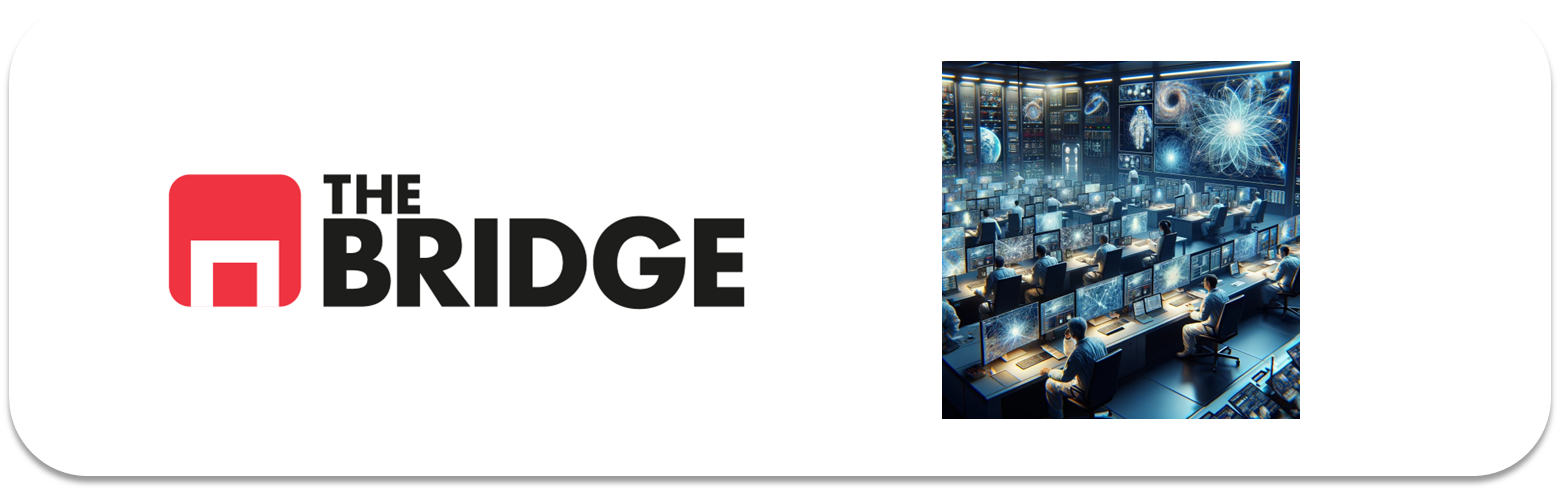

*RECUERDA QUE ESTE NOTEBOOK ES PARA QUE LO EJECUTES EN TU ORDENADOR, NO EN LA PLATAFORMA*


## Transfer Learning y Fine-tuning

Como hemos visto en la presentación, el **transfer learning** consiste en reutilizar un modelo entrenado para una tarea de origen (por ejemplo, clasificar las 1000 clases de ImageNet a partir de 1,28 millones de imágenes) como punto de partida para una tarea de destino relacionada pero distinta, en la que normalmente tenemos muchos menos datos. Funciona porque las primeras capas de una CNN aprenden características generales (bordes, texturas, formas) que sirven para casi cualquier imagen; las últimas, y sobre todo la cabeza densa, son específicas de la tarea original.

En este notebook veremos, con una misma red (**ResNet50V2**), tres formas de aprovechar un modelo preentrenado:

1. **Usarlo tal cual**, con su cabeza original: solo sirve si nuestras clases están entre las 1000 de ImageNet.
2. **Extracción de características** (fase 1): base congelada y una cabeza nueva entrenada con nuestros datos.
3. **Fine-tuning** (fase 2): partiendo del modelo anterior, descongelamos las últimas capas de la base y las reajustamos con un learning rate muy bajo.

### Qué modelo preentrenado elegir

Al final de la unidad anterior vimos varias arquitecturas convolucionales de referencia:

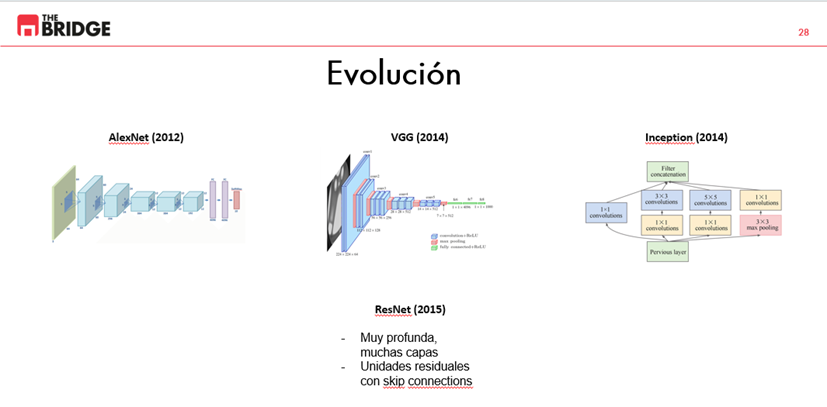

Todas ellas (y sus evoluciones) están disponibles en [Keras Applications](https://keras.io/api/applications/) en dos versiones: **solo la arquitectura** (`weights=None`, pesos aleatorios) o **con los pesos preentrenados en ImageNet** (`weights="imagenet"`). Para hacer transfer learning necesitamos, evidentemente, la segunda: lo que se transfiere son precisamente los pesos.

¿Cuál escoger? Una guía rápida (datos de Keras Applications, top-1 sobre la validación de ImageNet):

| Modelo | Parámetros | Tamaño | Top-1 ImageNet | Comentario |
|---|---|---|---|---|
| MobileNetV2 | 3,5 M | 14 MB | 71,3 % | Muy ligera: móvil y equipos modestos |
| EfficientNetB0 | 5,3 M | 29 MB | 77,1 % | Gran equilibrio precisión/tamaño |
| ResNet50 | 25,6 M | 98 MB | 74,9 % | La clásica, la que usaremos aquí (en su versión V2) |
| InceptionV3 | 23,9 M | 92 MB | 77,9 % | Muy usada en imagen médica |
| Xception | 22,9 M | 88 MB | 79,0 % | Más precisa que ResNet50, tamaño similar |
| EfficientNetV2S | 21,6 M | 88 MB | 83,9 % | La más precisa de la tabla |
| VGG16 | 138,4 M | 528 MB | 71,3 % | Pesada y poco precisa: hoy conviene evitarla |

Empieza por un modelo ligero y sube de tamaño si te quedas corto. Y, sobre todo, usa siempre **el `preprocess_input` y el tamaño de entrada propios de cada modelo**: la red solo "entiende" las imágenes si les aplicamos la misma normalización que se usó al preentrenarla.

Empezamos con los imports:

In [1]:
import os
import random

import cv2 # opencv
import kagglehub
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from skimage.io import imread
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.utils import shuffle

keras.utils.set_random_seed(42) # Para que los entrenamientos sean (casi) reproducibles

***

### 1. Usar el modelo preentrenado tal cual (sin reentrenar)

La red que vamos a usar es **ResNet50V2**:

<img src="./img/ResNet50.png" alt="drawing" width="600"/>

Lo primero que vamos a probar es lo más sencillo: descargar la red completa, **con su cabeza de clasificación original** (`include_top=True`), adaptar nuestras imágenes a su entrada (224x224 y su `preprocess_input`) y predecir directamente. No hay ningún entrenamiento: la red solo puede contestar con alguna de las **1000 clases de ImageNet** con las que se entrenó.

> **Ojo, esto no es *zero-shot learning*.** En zero-shot el modelo clasifica en categorías que nunca ha visto en entrenamiento, a partir de una descripción de las mismas (por ejemplo, "una foto de una radiografía con neumonía"). Una CNN con 1000 clases fijas no puede hacer eso: para zero-shot (o few-shot, con unos pocos ejemplos en el prompt) hacen falta modelos que entiendan descripciones, como los LLM para texto o modelos multimodales como CLIP para imágenes.

In [2]:
from keras.applications.resnet_v2 import ResNet50V2, decode_predictions, preprocess_input

In [3]:
# include_top=True -> incluye la cabeza densa original (1000 clases de ImageNet, activación softmax).
#                     Con la cabeza incluida la entrada está fijada a 224x224x3.
# weights="imagenet" -> pesos preentrenados en ImageNet (https://www.image-net.org/)
modelo_imagenet = ResNet50V2(include_top=True, weights="imagenet")

print("Entrada:", modelo_imagenet.input_shape)
print("Salida:", modelo_imagenet.output_shape)
print("Capas:", len(modelo_imagenet.layers), "- Parámetros:", f"{modelo_imagenet.count_params():,}")

102869336/102869336 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Entrada: (None, 224, 224, 3)
Salida: (None, 1000)
Capas: 192 - Parámetros: 25,613,800


*Si quieres ver todas sus capas puedes hacer `modelo_imagenet.summary()` (son 192, la salida es muy larga).*

Cargamos algunas imágenes de la carpeta `img` y las redimensionamos a 224x224:

In [4]:
def read_images(path, size = (224, 224)):
    X = []
    nombres = []
    for file in sorted(os.listdir(path)):
        if file.endswith((".jpg", ".jpeg")):
            image = imread(os.path.join(path, file))[:, :, :3] # Nos quedamos con los 3 canales RGB
            X.append(cv2.resize(image, size))
            nombres.append(file)
    return np.array(X), nombres

x_figs, nombres = read_images("img")
print(x_figs.shape, x_figs.dtype)
print(nombres)

(10, 224, 224, 3) uint8
['bear-1.jpg', 'bond.jpg', 'cat.8016.jpg', 'cat.8037.jpg', 'dog.11856.jpg', 'dog.11857.jpg', 'horse.jpg', 'karate.jpg', 'novia.jpeg', 'pizza.jpg']


Aplicamos el preprocesado propio de ResNet50V2 (lleva los píxeles de [0, 255] a [-1, 1]) y predecimos, sin tocar nada más en el modelo:

In [5]:
x_prep = preprocess_input(x_figs.astype("float32"))
print(x_prep.min(), x_prep.max())

preds = modelo_imagenet.predict(x_prep)
print(preds.shape) # Una probabilidad para cada una de las 1000 clases de ImageNet

-1.0 1.0
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
(10, 1000)


`decode_predictions` traduce esas 1000 probabilidades a las etiquetas de ImageNet. Mostramos cada imagen junto a sus 5 clases más probables:

35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step


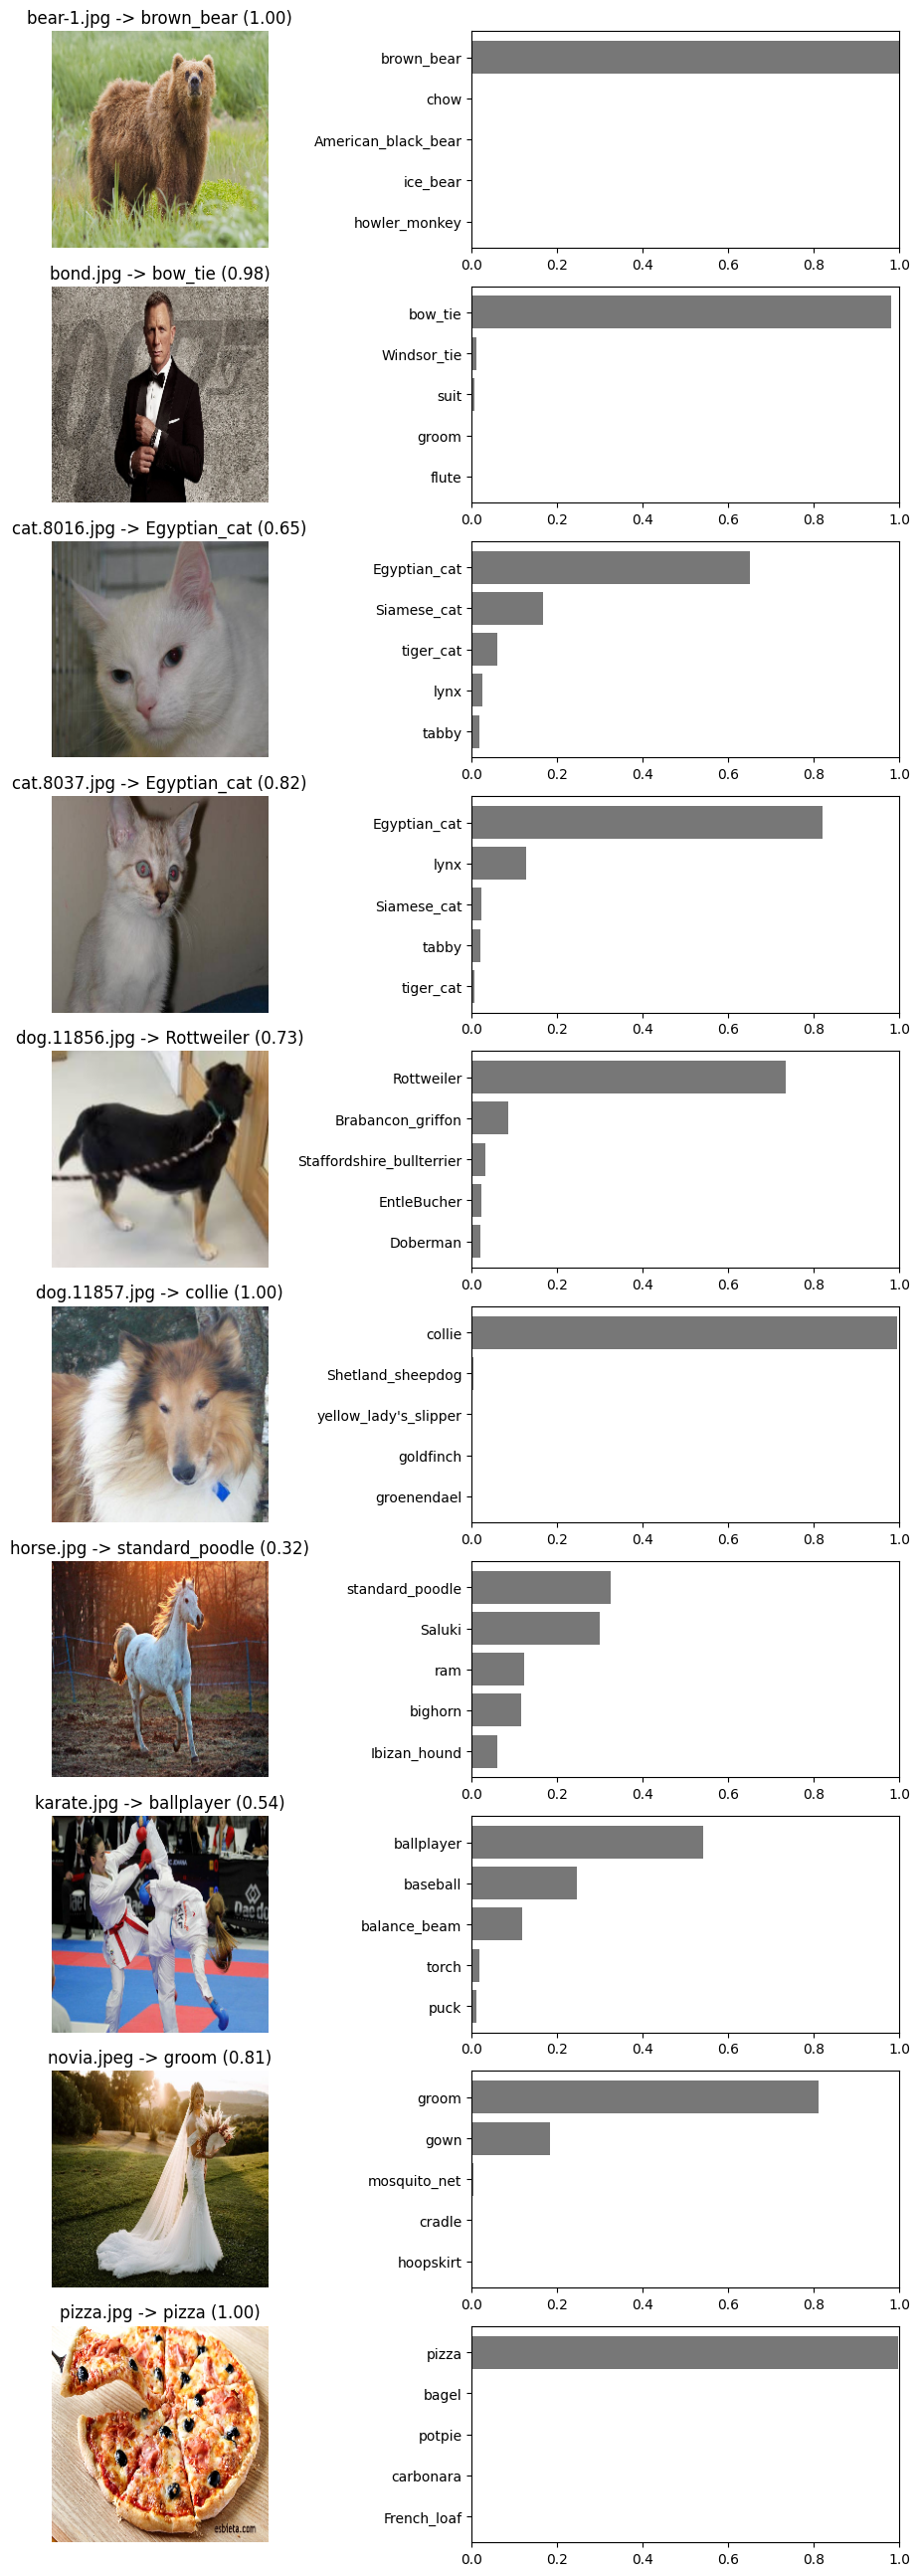

In [6]:
top5 = decode_predictions(preds, top=5) # Lista de (id_clase, nombre, probabilidad) por imagen

fig, axs = plt.subplots(len(x_figs), 2, figsize=(10, 2.6 * len(x_figs)))
for i, (img, decod) in enumerate(zip(x_figs, top5)):
    clases = [d[1] for d in decod]
    probs = [d[2] for d in decod]
    axs[i, 0].imshow(img)
    axs[i, 0].set_title(f"{nombres[i]} -> {clases[0]} ({probs[0]:.2f})")
    axs[i, 0].axis("off")
    axs[i, 1].barh(clases[::-1], probs[::-1], color="#777777")
    axs[i, 1].set_xlim(0, 1)
plt.tight_layout()
plt.show()

*Cuando lo que aparece en la imagen es una de las 1000 clases de ImageNet el resultado es espectacular: el oso (`brown_bear`), la pizza o el collie salen con una confianza de prácticamente 1, y los gatos y perros caen en razas concretas (`Egyptian_cat`, `Rottweiler`...), porque ImageNet distingue más de un centenar de razas de perro y varias de gato.*

*Pero fíjate en el resto: ImageNet **no tiene una clase "persona"** (y de caballos solo tiene `sorrel`, el alazán), así que la red contesta con lo más parecido que conoce: la foto de James Bond es una `bow_tie` (pajarita), la novia es un `groom` (novio) o un `gown` (vestido), el karate es un `ballplayer` y el caballo, con muy poca confianza, un `standard_poodle`. La red no puede aprender clases nuevas sin reentrenarla: para eso está el transfer learning.*

***

### 2. Nuestro problema: perros y gatos

Para las dos fases de transfer learning vamos a usar las imágenes de perros y gatos de la práctica de la unidad anterior. Las descargamos de Kaggle con `kagglehub` (ya viene instalado en Colab; en local `pip install kagglehub`), que las deja en una caché de tu carpeta de usuario, fuera del repositorio.

Como vamos a trabajar en CPU, nos quedamos con una muestra aleatoria (con semilla) de 1000 imágenes por clase para train y 250 por clase para test, a 160x160 píxeles. Fíjate en que con transfer learning **no necesitamos las 20000 imágenes**: ese es uno de sus puntos fuertes.

In [7]:
PATH_DATA = kagglehub.dataset_download("salader/dogsvscats")

IMG_SIZE = 160
N_TRAIN_POR_CLASE = 1000
N_TEST_POR_CLASE = 250

def read_data(subdirectorio, n_por_clase, reshape_dim = (IMG_SIZE, IMG_SIZE), random_state = 42):
    rng = random.Random(random_state)
    X = []
    y = []
    for clase in sorted(os.listdir(os.path.join(PATH_DATA, subdirectorio))): # cats, dogs
        ficheros = rng.sample(sorted(os.listdir(os.path.join(PATH_DATA, subdirectorio, clase))), n_por_clase)
        for fichero in ficheros:
            image = imread(os.path.join(PATH_DATA, subdirectorio, clase, fichero))
            X.append(cv2.resize(image, reshape_dim))
            y.append(clase)
    return np.array(X), np.array(y)

X_train, y_train = read_data("train", N_TRAIN_POR_CLASE)
X_test, y_test = read_data("test", N_TEST_POR_CLASE)
print(X_train.shape, X_test.shape, X_train.dtype)

(2000, 160, 160, 3) (500, 160, 160, 3) uint8


Pasamos el target a 0/1 (gato/perro) y barajamos el train. Esto último es imprescindible: `validation_split` **no baraja**, se queda con el último 20 % de los datos, y los nuestros están ordenados (primero todos los gatos y luego todos los perros).

Fíjate también en que **no escalamos** las imágenes: el `preprocess_input` de ResNet50V2 irá dentro del propio modelo, así el modelo recibe siempre píxeles en [0, 255] (en train, en test y en producción) y no hay forma de olvidarse de preprocesar.

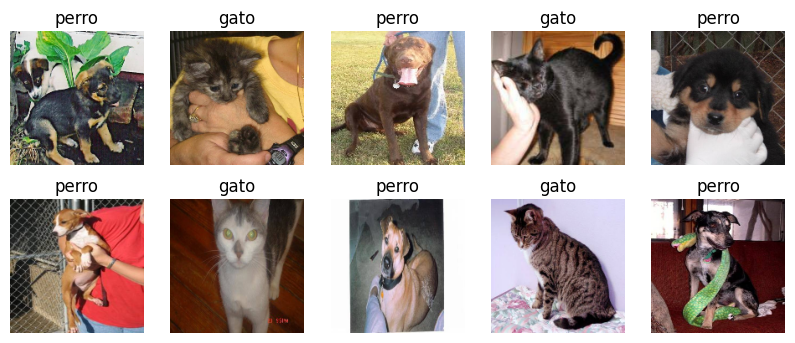

In [8]:
y_train_num = (y_train == "dogs").astype(int)
y_test_num = (y_test == "dogs").astype(int)

X_train_s, y_train_s = shuffle(X_train, y_train_num, random_state=42)

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train_s[i])
    plt.title(["gato", "perro"][y_train_s[i]])
    plt.axis("off")
plt.show()

***

### 3. Fase 1: extracción de características (base congelada)

Ahora cargamos ResNet50V2 **sin su cabeza** (`include_top=False`): nos quedamos con la parte convolucional, que convierte cada imagen en un mapa de características, y le añadimos una cabeza nueva para nuestras 2 clases. Seguimos la receta de la presentación:

1. `base_model.trainable = False`: congelamos toda la base; solo se entrenará la cabeza nueva.
2. Aumentado de imágenes con capas de Keras (`RandomFlip`, `RandomRotation`, `RandomZoom`): solo actúan durante el entrenamiento.
3. `preprocess_input` dentro del modelo.
4. Llamamos a la base con `training=False`. Así sus capas de **BatchNormalization** funcionan siempre en modo inferencia (con las medias y varianzas aprendidas en ImageNet), también cuando más adelante la descongelemos. Si las dejáramos actualizar esas estadísticas con nuestro pequeño dataset destrozarían lo aprendido.
5. `GlobalAveragePooling2D` para pasar del mapa de características (de 5x5x2048 con entradas de 160x160) a un vector de 2048: tiene muchos menos parámetros que un `Flatten` seguido de una capa densa grande y sobreajusta menos.
6. Una salida sigmoide (problema binario).

In [9]:
base_model = ResNet50V2(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False # (1) congelamos la base

aumentado = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
], name="aumentado")

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = aumentado(inputs)                        # (2) aumentado, solo en entrenamiento
x = preprocess_input(x)                      # (3) [0, 255] -> [-1, 1]
x = base_model(x, training=False)            # (4) BatchNorm siempre en modo inferencia
x = keras.layers.GlobalAveragePooling2D()(x) # (5) 5x5x2048 -> 2048
x = keras.layers.Dropout(0.3)(x)
outputs = keras.layers.Dense(1, activation="sigmoid")(x) # (6) cabeza nueva

model = keras.Model(inputs, outputs)
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumentado (Sequential)          │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 5, 5, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,566,849 (89.90 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,564,800 (89.89 MB)

Observa en el resumen que de los más de 23 millones de parámetros solo son entrenables los 2049 de la capa de salida: todo lo demás son pesos de ImageNet congelados. Entrenamos con un learning rate normal (el de Adam por defecto) y `EarlyStopping`:

In [10]:
early_stopping = keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)

history_fase1 = model.fit(X_train_s, y_train_s,
                          validation_split=0.2,
                          batch_size=32,
                          epochs=15,
                          callbacks=[early_stopping])

Epoch 1/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 57s 869ms/step - accuracy: 0.7292 - loss: 0.6306 - val_accuracy: 0.9550 - val_loss: 0.1197
Epoch 2/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 33s 656ms/step - accuracy: 0.9284 - loss: 0.1767 - val_accuracy: 0.9700 - val_loss: 0.1001
Epoch 3/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 31s 628ms/step - accuracy: 0.9344 - loss: 0.1737 - val_accuracy: 0.9625 - val_loss: 0.0988
Epoch 4/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 29s 591ms/step - accuracy: 0.9473 - loss: 0.1424 - val_accuracy: 0.9600 - val_loss: 0.0896
Epoch 5/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 30s 604ms/step - accuracy: 0.9510 - loss: 0.1139 - val_accuracy: 0.9725 - val_loss: 0.0832
Epoch 6/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 30s 601ms/step - accuracy: 0.9591 - loss: 0.1002 - val_accuracy: 0.9750 - val_loss: 0.0782
Epoch 7/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 30s 607ms/step - accuracy: 0.9629 - loss: 0.0959 - val_accuracy: 0.9650 - val_loss: 0.0744
Epoch 8/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 30s 612ms/step - accuracy: 0.9504 - loss: 0.1239 - val_accu

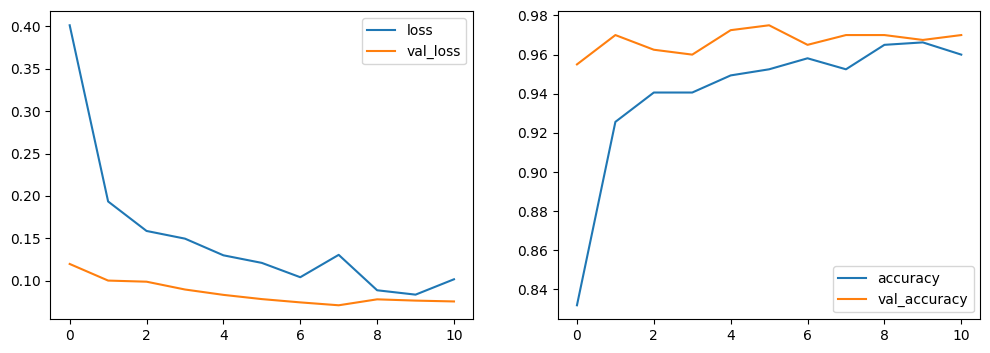

In [11]:
evol_fase1 = pd.DataFrame(history_fase1.history)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
evol_fase1[["loss", "val_loss"]].plot(ax=axs[0])
evol_fase1[["accuracy", "val_accuracy"]].plot(ax=axs[1])
plt.show()

*Con solo 1600 imágenes de entrenamiento y entrenando únicamente 2049 parámetros, ya en la primera época la validación supera el 95 % de accuracy, y el EarlyStopping se queda con la época de menor `val_loss` (la 8, con un 97 %). Es lo que esperábamos: las características que ResNet50V2 aprendió con ImageNet (que incluye muchas razas de perros y gatos) sirven casi directamente para nuestro problema. Compara con el 72-78 % en test de la CNN que entrenamos desde cero en la práctica de la unidad anterior (eso sí, con imágenes de 32x32).*

*No te extrañe que la accuracy de train quede por debajo de la de validación: en train el modelo ve imágenes aumentadas y con Dropout activo, que son más difíciles que las de validación.*

> **Truco:** como la base está congelada y en modo inferencia, en esta fase podríamos **precalcular** las características de todas las imágenes una sola vez (`base_model.predict`) y entrenar la cabeza sobre ellas, lo que es muchísimo más rápido. El precio es renunciar al aumentado de imágenes, que necesita pasar por la base en cada época.

***

### 4. Fase 2: fine-tuning (descongelar las últimas capas)

Una vez que la cabeza ha convergido, podemos intentar mejorar **reajustando ligeramente** las capas más específicas de la base. Las reglas importantes:

* Descongelamos **solo las últimas capas** (aquí, el último bloque de ResNet50V2: las capas cuyo nombre empieza por `conv5` y la `post_bn` final). Las primeras capas aprenden características generales que no hace falta tocar.
* Las capas de **BatchNormalization** las dejamos congeladas (y, además, la base sigue llamándose con `training=False`).
* **Hay que volver a compilar** el modelo para que el cambio en `trainable` tenga efecto.
* Usamos un **learning rate muy bajo** (1e-5). Con un learning rate normal los pasos de actualización serían demasiado grandes y destrozarían los pesos preentrenados (*olvido catastrófico*).
* Solo tiene sentido **después** de la fase 1: si descongeláramos la base con una cabeza recién inicializada (pesos aleatorios), sus gradientes enormes se propagarían hacia la base y estropearían lo aprendido.

In [12]:
base_model.trainable = True
for layer in base_model.layers:
    es_ultimo_bloque = layer.name.startswith(("conv5", "post_bn"))
    if not es_ultimo_bloque or isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

print("Capas entrenables de la base:", sum(layer.trainable for layer in base_model.layers), "de", len(base_model.layers))

model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5), # learning rate muy bajo
              loss="binary_crossentropy",
              metrics=["accuracy"])
model.summary()

Capas entrenables de la base: 25 de 190


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumentado (Sequential)          │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 5, 5, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,566,849 (89.90 MB)

 Trainable params: 14,952,449 (57.04 MB)

 Non-trainable params: 8,614,400 (32.86 MB)

Ahora hay muchos más parámetros entrenables (los del último bloque). Continuamos el entrenamiento desde donde lo dejamos, con la misma validación, para poder comparar:

In [13]:
history_fase2 = model.fit(X_train_s, y_train_s,
                          validation_split=0.2,
                          batch_size=32,
                          epochs=10,
                          callbacks=[early_stopping])

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 90s 1s/step - accuracy: 0.9607 - loss: 0.1122 - val_accuracy: 0.9650 - val_loss: 0.0776
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 74s 1s/step - accuracy: 0.9677 - loss: 0.0838 - val_accuracy: 0.9700 - val_loss: 0.0704
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step - accuracy: 0.9885 - loss: 0.0387 - val_accuracy: 0.9700 - val_loss: 0.0803
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 74s 1s/step - accuracy: 0.9755 - loss: 0.0591 - val_accuracy: 0.9700 - val_loss: 0.0665
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 76s 2s/step - accuracy: 0.9862 - loss: 0.0402 - val_accuracy: 0.9725 - val_loss: 0.0735
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 74s 1s/step - accuracy: 0.9881 - loss: 0.0361 - val_accuracy: 0.9825 - val_loss: 0.0638
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 61s 1s/step - accuracy: 0.9883 - loss: 0.0383 - val_accuracy: 0.9800 - val_loss: 0.0592
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 38s 762ms/step - accuracy: 0.9934 - loss: 0.0216 - val_accuracy: 0.9750 - val_lo

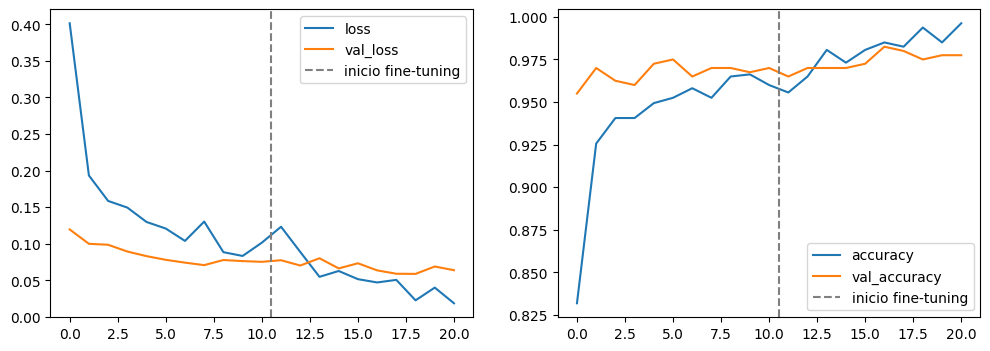

Mejor época fase 1: 8 - val_loss: 0.0709, val_accuracy: 0.9700
Mejor época fase 2: 8 - val_loss: 0.0590, val_accuracy: 0.9750


In [14]:
evol = pd.concat([evol_fase1, pd.DataFrame(history_fase2.history)], ignore_index=True)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, metrica in zip(axs, ["loss", "accuracy"]):
    evol[[metrica, "val_" + metrica]].plot(ax=ax)
    ax.axvline(len(evol_fase1) - 0.5, color="grey", linestyle="--", label="inicio fine-tuning")
    ax.legend()
plt.show()

# EarlyStopping se queda con la época de menor val_loss: comparamos esas épocas
evol_fase2 = pd.DataFrame(history_fase2.history)
for fase, ev in [("fase 1", evol_fase1), ("fase 2", evol_fase2)]:
    mejor = ev["val_loss"].idxmin()
    print(f"Mejor época {fase}: {mejor + 1} - val_loss: {ev['val_loss'][mejor]:.4f}, val_accuracy: {ev['val_accuracy'][mejor]:.4f}")

*El fine-tuning arranca justo donde terminó la fase 1, sin ningún salto en la pérdida: gracias al learning rate tan bajo, los pesos preentrenados solo se reajustan ligeramente. La pérdida de validación sigue bajando (de 0,071 a 0,059) y la accuracy de validación sube algo, del 97 % al 97,5 %. Es una mejora modesta porque la fase 1 ya era muy buena: perros y gatos se parecen mucho a la tarea de origen. El fine-tuning aporta más cuanto más distinto es nuestro dominio del de ImageNet (y cuantos más datos tenemos). Ojo también a la accuracy de train, que al final se acerca al 100 %: con más épocas empezaríamos a sobreajustar.*

Con el modelo final, y solo ahora, lo evaluamos contra test:

16/16 ━━━━━━━━━━━━━━━━━━━━ 13s 814ms/step - accuracy: 0.9642 - loss: 0.1213
test loss, test acc: [0.10752852261066437, 0.9679999947547913]
16/16 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step
              precision    recall  f1-score   support

        gato       0.97      0.97      0.97       250
       perro       0.97      0.97      0.97       250

    accuracy                           0.97       500
   macro avg       0.97      0.97      0.97       500
weighted avg       0.97      0.97      0.97       500



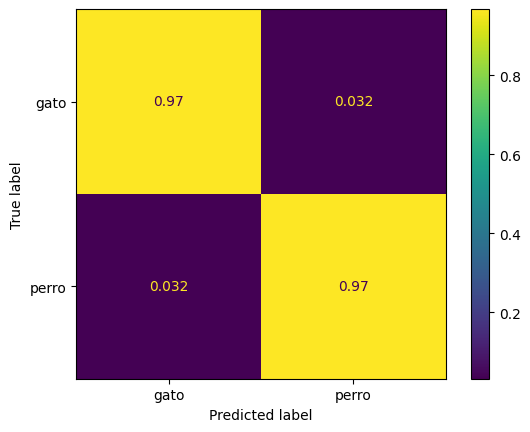

In [15]:
results = model.evaluate(X_test, y_test_num)
print("test loss, test acc:", results)

y_pred = (model.predict(X_test).ravel() > 0.5).astype(int)
print(classification_report(y_test_num, y_pred, target_names=["gato", "perro"]))
ConfusionMatrixDisplay.from_predictions(y_test_num, y_pred, display_labels=["gato", "perro"], normalize="true")
plt.show()

*Un 96,8 % de accuracy en test, muy en línea con la validación y equilibrado entre gatos y perros, entrenando solo con 2000 imágenes de 160x160 y unos minutos de CPU por época. Ese es el gran atractivo del transfer learning.*

***

### 5. Resumen y precauciones

* **Extracción de características** (base congelada, solo cabeza nueva): pocos datos, barato, buen resultado si la tarea se parece a la de origen.
* **Fine-tuning** (cabeza + últimas capas, o toda la red si hay muchos datos): siempre después de la fase 1, con learning rate muy bajo (≈1e-5), recompilando y con `EarlyStopping`.
* **Preprocesado**: mismo tamaño de entrada y misma normalización (`preprocess_input`) que en el preentrenamiento.
* **BatchNormalization**: llama a la base con `training=False`.
* **Riesgos**: *sobreajuste* (pocos datos y muchas capas descongeladas: usa aumentado, regularización y más capas congeladas), *olvido catastrófico* (learning rate demasiado alto) y *transferencia negativa* (si origen y destino se parecen poco, transferir puede incluso empeorar; ahí conviene probar a reutilizar menos capas).

> **Nota:** no todos los modelos se transfieren exactamente igual. La filosofía es la misma, pero cuando vayas a usar uno lee las instrucciones que lo acompañan en el repositorio del que lo descargues (tamaño de entrada, preprocesado, qué capas descongelar...).

### Repositorios de modelos

Algunos repositorios de modelos preentrenados:

* [Aplicaciones de Keras](https://keras.io/api/applications/)
* [Kaggle Models (antes TensorFlow Hub)](https://www.kaggle.com/models)
* [PyTorch Hub](https://pytorch.org/hub/)
* [Hugging Face Hub](https://huggingface.co/models) (y su librería [Transformers](https://huggingface.co/docs/transformers/index))